# Activity 4: K-Means and Hierarchical Clustering

## MLOps Investigation

MLOps [Machine Learning Operations, the practice of taking a model all the way from raw data to a saved model that can be used on new data] is the focus of this activity. The work follows five phases: problem formulation, data preparation, model training, evaluation, and deployment.

### Scenario

A botanical research institute has measurements from 150 iris flowers. Each flower has four physical measurements: sepal length, sepal width, petal length, and petal width. The actual species labels exist, but they are not allowed to be used while the clustering is performed. They are kept aside and used later only to evaluate how well the clustering worked.

### Main Research Question

Can natural groups be discovered in the Iris dataset without giving the clustering algorithms the actual species labels?

This is an unsupervised learning problem [a machine-learning problem where the model looks for patterns or groups without being given the correct answers first]. The goal is to see whether the flower measurements naturally form groups before those groups are compared with the known species later.

## Phase 1: Problem Formulation and Data Fundamentals

Before any clustering model is run, the data needs to be understood and checked. This phase loads the Iris dataset, separates the measurements from the known species labels, checks the structure of the data, looks for missing values, and completes a basic data audit [a checklist review that confirms the data is complete and usable].

**Important:** The true species labels must not be used as input to the clustering algorithms. They are stored separately so they can be used later to check how well the clustering worked.

### 1.1 Import the Required Libraries

This step imports the tools needed and loads the Iris dataset. The dataset contains measurements from 150 iris flowers. At this point the data is only being loaded. No model is being trained yet.

In [1]:
# Phase 1
# Import the libraries we need and load the Iris data
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
# Load the Iris dataset
iris = load_iris()

In [2]:
# Confirm that the Iris dataset loaded successfully
print("Iris dataset loaded successfully.")
print("Number of flower records loaded:", iris.data.shape[0])

Iris dataset loaded successfully.
Number of flower records loaded: 150


The output confirms that the Iris dataset loaded successfully and contains 150 flower records.

### 1.2 Separate Features from True Labels

The dataset contains both flower measurements and the actual species answers. These need to be separated before clustering.

- `X` contains the features [the measurable pieces of information the model is allowed to use], such as sepal length and petal width.
- `y_true` contains the true labels [the actual species each flower belongs to]. These labels are kept separate because giving them to the clustering algorithm would basically hand it the answers.

Each row is one observation [one flower in the dataset]. Each column is one feature. The feature names describe the columns. They are not values used to form the clusters.

The code also builds `df`, a DataFrame [a table with labelled rows and columns, similar to a spreadsheet] that holds only the four measurements. It also shows descriptive statistics [a quick number summary of each column, such as the mean, minimum, and maximum].

In [3]:
# X contains the physical measurements of the flowers
# The clustering algorithms will use X
X = iris.data
# y_true contains the actual species labels
# We keep this separate and DO NOT use it for clustering
y_true = iris.target
# Store feature and class names for later reference
feature_names = iris.feature_names
class_names = iris.target_names
# Convert X into a DataFrame for easier inspection
df = pd.DataFrame(X, columns=feature_names)
# Check the structure of the DataFrame
print("DataFrame information:")
df.info()
print("=" * 70)
# Display descriptive statistics
print("Descriptive statistics:")
display(df.describe())
print("=" * 70)
# Check the shape of X and y_true
print("X shape:", X.shape)
print("y_true shape:", y_true.shape)
print("=" * 70)
# Display the names of the four features
print("Features:")
for feature in feature_names:
    print("-", feature)
print("=" * 70)
# Display the actual species names
print("True classes:")
for class_name in class_names:
    print("-", class_name)

DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
Descriptive statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


X shape: (150, 4)
y_true shape: (150,)
Features:
- sepal length (cm)
- sepal width (cm)
- petal length (cm)
- petal width (cm)
True classes:
- setosa
- versicolor
- virginica


In [4]:
# Summary table built from the loaded data (no values are typed in by hand)
dataset_summary = pd.DataFrame({
    "Measure": [
        "Number of observations",
        "Number of features",
        "Number of known species",
        "X shape",
        "y_true shape",
    ],
    "Value": [
        str(X.shape[0]),
        str(X.shape[1]),
        str(len(class_names)),
        str(X.shape),
        str(y_true.shape),
    ],
})

dataset_summary

,Measure,Value
0,Number of observations,150
1,Number of features,4
2,Number of known species,3
3,X shape,"(150, 4)"
4,y_true shape,"(150,)"


### How to Read This

Each row represents one flower, and each feature column represents one physical measurement. There are four measurements available for clustering. The species information exists, but it is stored separately in `y_true` and is not used to create the clusters.

### Takeaway

The dataset has the expected structure for this activity: 150 flower observations with four numerical features. The measurements are stored in `X`, and the real species labels are kept separately in `y_true` for later validation [checking the results against the known answers after the model is finished].

### 1.3 Check the Class Distribution

A class distribution [a count of how many observations belong to each category] shows whether the dataset is balanced [each group has about the same number of examples]. The species labels are inspected here only as part of the data audit. They are not used by K-Means or Hierarchical Clustering.

In [5]:
# Check how many observations belong to each true class
class_counts = np.bincount(y_true)
print("Class distribution:", class_counts)

Class distribution: [50 50 50]


In [6]:
# Same counts shown with the real species names and percentages
class_distribution = pd.DataFrame({
    "Species": [name.title() for name in class_names],
    "Flower Count": class_counts,
})

percentages = class_distribution["Flower Count"] / class_distribution["Flower Count"].sum() * 100
class_distribution["Percentage of Dataset"] = [f"{p:.1f}%" for p in percentages]

class_distribution

,Species,Flower Count,Percentage of Dataset
0,Setosa,50,33.3%
1,Versicolor,50,33.3%
2,Virginica,50,33.3%


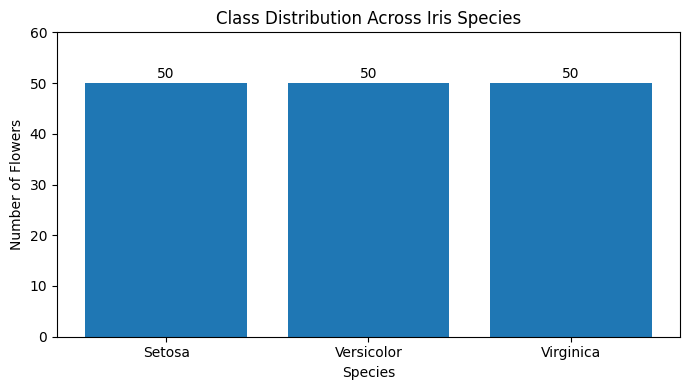

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.bar(class_distribution["Species"], class_distribution["Flower Count"])

# Show the count above each bar so the exact number is easy to read
for i, count in enumerate(class_distribution["Flower Count"]):
    plt.text(i, count + 1, str(count), ha="center")

plt.title("Class Distribution Across Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")
plt.ylim(0, class_distribution["Flower Count"].max() + 10)
plt.tight_layout()
plt.show()

### How to Read This

The output `[50 50 50]` lists the flower count for each species in order: Setosa, Versicolor, and Virginica. The table and bar chart show the same counts with the species names. These labels are inspected only as part of the data audit. They are not given to K-Means or Ward's clustering.

### Takeaway

The dataset is balanced. Setosa, Versicolor, and Virginica each contain 50 flowers, so each species represents about 33.3% of the 150 observations. This gives useful context for later evaluation, but the species labels stay separate during clustering.

### 1.4 Check for Missing Values

Missing values [blank or unavailable data entries] can cause problems for machine-learning algorithms. Before clustering, the four flower measurements are checked for missing entries. `X_df` is a DataFrame copy of `X` that holds only the four measurements.

In [8]:
# Convert X to a DataFrame and check for missing values
X_df = pd.DataFrame(X, columns=feature_names)
missing_values = X_df.isnull().sum().sum()
print("Total missing values:", missing_values)

Total missing values: 0


In [9]:
# Missing-value count for each feature, plus a total row
missing_per_feature = X_df.isnull().sum()

missing_table = pd.DataFrame({
    "Feature": missing_per_feature.index,
    "Missing Values": missing_per_feature.values,
})

total_row = pd.DataFrame({
    "Feature": ["Total"],
    "Missing Values": [missing_per_feature.sum()],
})

missing_table = pd.concat([missing_table, total_row], ignore_index=True)

missing_table

,Feature,Missing Values
0,sepal length (cm),0
1,sepal width (cm),0
2,petal length (cm),0
3,petal width (cm),0
4,Total,0


### Takeaway

The table confirms that there are no missing values in the Iris feature data. No rows need to be removed and no measurements need to be filled in before clustering.

### 1.5 Check Data Types and the First Five Observations

This step confirms what kind of values are stored in each feature and shows a few actual rows. A data type [the kind of value stored in a column, such as a number or text] matters because the clustering algorithms need numerical measurements for their distance calculations.

In [10]:
# Display the data types of the four features
print("Feature data types:")
print(X_df.dtypes)
print("=" * 70)
# Display the first five observations
print("First five observations:")
display(X_df.head())
print("=" * 70)
# Display the first five true labels
print("First five y_true values:")
print(y_true[:5])
print("\nTrue class names:")
print(class_names[y_true[:5]])

Feature data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object
First five observations:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


First five y_true values:
[0 0 0 0 0]

True class names:
['setosa' 'setosa' 'setosa' 'setosa' 'setosa']


In [11]:
# Data types shown as a table
dtype_table = pd.DataFrame({
    "Feature": X_df.columns,
    "Data Type": X_df.dtypes.astype(str).values,
})

dtype_table

,Feature,Data Type
0,sepal length (cm),float64
1,sepal width (cm),float64
2,petal length (cm),float64
3,petal width (cm),float64


### How to Read This

The data type table shows the type of numerical data stored in each feature. The first-five-observations table shows the first five flower records and their measurements. The true labels printed afterward are included only to verify the dataset during the audit.

### Takeaway

All four clustering features are stored as `float64` [decimal numbers], which means they can be used in the distance calculations required later by K-Means and Ward's Hierarchical Clustering. The first observations also confirm that the measurements loaded correctly. The first five flowers all belong to Setosa (label 0).

### 1.6 Final Phase 1 Data Audit

This final audit puts the important Phase 1 checks in one place. It confirms that the data is complete, numerical, correctly shaped, and separated properly before preprocessing [preparing the data so it is ready for a model].

In [12]:
# Final Phase 1 data audit
print("=" * 70)
print("PHASE 1: PROBLEM FORMULATION & DATA AUDIT")
print("=" * 70)
print(f"Number of observations: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print(f"Feature names: {feature_names}")
print(f"True classes: {class_names}")
print(f"Class distribution: {np.bincount(y_true)}")
print(
    f"Missing values: "
    f"{pd.DataFrame(X, columns=feature_names).isnull().sum().sum()}")
print("\nX shape:", X.shape)
print("y_true shape:", y_true.shape)
print("\nX = features used by clustering")
print("y_true = true labels reserved for later validation")
print("\n ✓ Phase 1 data audit complete")

PHASE 1: PROBLEM FORMULATION & DATA AUDIT
Number of observations: 150
Number of features: 4
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
True classes: ['setosa' 'versicolor' 'virginica']
Class distribution: [50 50 50]
Missing values: 0

X shape: (150, 4)
y_true shape: (150,)

X = features used by clustering
y_true = true labels reserved for later validation

 ✓ Phase 1 data audit complete


In [13]:
# Final audit shown as one table
audit_table = pd.DataFrame({
    "Check": [
        "Observations",
        "Features",
        "Feature names",
        "Known species",
        "Class distribution",
        "Missing values",
        "X shape",
        "y_true shape",
        "Clustering input",
        "Labels reserved for validation",
    ],
    "Result": [
        str(X.shape[0]),
        str(X.shape[1]),
        ", ".join(feature_names),
        ", ".join(name.title() for name in class_names),
        ", ".join(f"{name.title()}: {count}" for name, count in zip(class_names, np.bincount(y_true))),
        str(int(X_df.isnull().sum().sum())),
        str(X.shape),
        str(y_true.shape),
        f"X only ({X.shape[1]} measurement columns)",
        "y_true (kept separate, not used for clustering)",
    ],
})

audit_table

,Check,Result
0,Observations,150
1,Features,4
2,Feature names,"sepal length (cm), sepal width (cm), petal length (cm), petal width (cm)"
3,Known species,"Setosa, Versicolor, Virginica"
4,Class distribution,"Setosa: 50, Versicolor: 50, Virginica: 50"
5,Missing values,0
6,X shape,"(150, 4)"
7,y_true shape,"(150,)"
8,Clustering input,X only (4 measurement columns)
9,Labels reserved for validation,"y_true (kept separate, not used for clustering)"


### Phase 1 Takeaway

Phase 1 confirms that the Iris dataset is ready for preprocessing. The data has 150 complete observations, four numerical features, no missing feature values, and three balanced known species. Most importantly, `X` contains only the measurements that clustering is allowed to use, while `y_true` stays separate for later validation.

## Phase 1 Questions

### Q1: What is the business/research problem we are trying to solve?

The research problem is to determine whether the 150 Iris flowers naturally form meaningful groups based only on their four physical measurements, without giving the clustering algorithms the known species labels. Later, the discovered groups can be compared with the actual species to see how closely they align.

### Q6: Can we merge X and y_true and use them together as input to K-Means? Explain.

No. `X` and `y_true` should not be merged and used together as input to K-Means because `y_true` contains the known species answers. The purpose of this activity is for the algorithm to discover groups using only the flower measurements. Including the known labels would leak information the model is supposed to discover on its own and would no longer be a proper unsupervised learning setup.

### Q7: What would happen if we gave y_true to K-Means as an input feature?

If `y_true` were added as an input feature, K-Means would treat the species IDs as numerical information and include them in its distance calculations. That would leak the correct species information into the clustering process and could make the clusters appear more successful than they really are.

## Phase 2: Data Preparation and Feature Engineering

This phase prepares the four features for clustering. The goals are to:

- standardize the four features,
- confirm that the standardized data has a mean of about 0 and a standard deviation of about 1,
- keep the fitted scaler for use during deployment,
- prepare a two-feature subset for visualization only.

### 2.1 Standardize the Features

K-Means and Ward's Hierarchical Clustering both rely on distance calculations [measuring how far apart two flowers are, using their feature values]. The four Iris features do not vary by the same amount. A feature with a much larger spread can have a bigger influence on the distance than the others.

To prevent this, the features are standardized. Standardization [rescaling numerical features so they are measured on a comparable scale] changes each feature so that it has a mean [average] of 0 and a standard deviation [a measure of how spread out the values are] of 1.

`StandardScaler` is the scikit-learn tool that does this. It is fitted [it learns the mean and standard deviation of each feature from the data] and then used to transform [apply those learned values to rescale the data].

In [14]:
# Phase 2
# Import the scaler
from sklearn.preprocessing import StandardScaler
# Create the scaler
scaler = StandardScaler()
# Fit the scaler using X and transform the data
X_scaled = scaler.fit_transform(X)
# Display Phase 2 information
print("=" * 70)
print("PHASE 2: DATA PREPARATION & FEATURE ENGINEERING")
print("=" * 70)
print("Original X shape:", X.shape)
print("Scaled X shape:", X_scaled.shape)
print("\nScaled feature means:")
print(X_scaled.mean(axis=0).round(4))
print("\nScaled feature standard deviations:")
print(X_scaled.std(axis=0).round(4))
print("\n Features standardized")
print("Fitted scaler stored in variable: scaler")

PHASE 2: DATA PREPARATION & FEATURE ENGINEERING
Original X shape: (150, 4)
Scaled X shape: (150, 4)

Scaled feature means:
[-0. -0. -0. -0.]

Scaled feature standard deviations:
[1. 1. 1. 1.]

 Features standardized
Fitted scaler stored in variable: scaler


In [15]:
# Before-and-after comparison for each feature
# (adding 0.0 turns any "-0.0" from rounding into a plain 0.0)
scaling_table = pd.DataFrame({
    "Feature": feature_names,
    "Original Mean": X.mean(axis=0).round(3),
    "Original Std": X.std(axis=0).round(3),
    "Scaled Mean": X_scaled.mean(axis=0).round(4) + 0.0,
    "Scaled Std": X_scaled.std(axis=0).round(4),
})

scaling_table

,Feature,Original Mean,Original Std,Scaled Mean,Scaled Std
0,sepal length (cm),5.843,0.825,0.0,1.0
1,sepal width (cm),3.057,0.434,0.0,1.0
2,petal length (cm),3.758,1.759,0.0,1.0
3,petal width (cm),1.199,0.760,0.0,1.0


### How to Read This

Each row is one feature. The "Original" columns show the average and spread of the real measurements in centimetres. The "Scaled" columns show the same features after standardization.

### Takeaway

Before scaling, the features had different spreads. Petal length had the largest standard deviation (about 1.759 cm) and sepal width had the smallest (about 0.434 cm). After scaling, every feature has a mean of 0 and a standard deviation of 1, so no single feature controls the distance calculations just because of its size.

### 2.2 Examine the Standardized Data

The original `X` contains the actual measurements. `X_scaled` contains the standardized versions of those same measurements.

In [16]:
# Create a DataFrame to make the scaled data easier to inspect
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_names)
print("\nFirst five rows of standardized data:")
display(X_scaled_df.head())


First five rows of standardized data:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


### How to Read This

Each value now shows how far a measurement is from that feature's average, counted in standard deviations. A negative value means the measurement is below average. A positive value means it is above average. For example, the first flower has a sepal width above average and petal measurements well below average, which fits the small petals of Setosa flowers.

### 2.3 Preserve the Scaler for Deployment

The scaler is part of the machine-learning pipeline [the full chain of steps that turns raw data into a model result]. When a new flower arrives later, its measurements must be rescaled using the same means and standard deviations that were learned from the original data. For this reason, the scaler must not be recreated or refitted using new flowers.

The deployment process will be:

New flower → Same scaler → Scaled new flower → K-Means model → Cluster

In [17]:
# Confirm that the scaler exists
print(scaler)

StandardScaler()


In [18]:
# Values the fitted scaler learned from the original data
scaler_parameters = pd.DataFrame({
    "Feature": feature_names,
    "Learned Mean (scaler.mean_)": scaler.mean_.round(4),
    "Learned Std (scaler.scale_)": scaler.scale_.round(4),
})

scaler_parameters

,Feature,Learned Mean (scaler.mean_),Learned Std (scaler.scale_)
0,sepal length (cm),5.8433,0.8253
1,sepal width (cm),3.0573,0.4344
2,petal length (cm),3.7580,1.7594
3,petal width (cm),1.1993,0.7597


### Takeaway

The output confirms that the fitted scaler exists and is stored in `scaler`. The table shows the exact means and standard deviations it learned. These same numbers will be used to rescale any new flower in Phase 5.

### 2.4 Prepare Data for Visualization

The clustering algorithms use all four features. A simple two-dimensional scatter plot, however, can only show two features at a time. For this activity, the first two features (sepal length and sepal width) are used for plotting.

In [19]:
# Select the first two features for visualization only
X_viz = X[:, :2]
print("Visualization data shape:", X_viz.shape)
print("\nVisualization features:")
print("-", feature_names[0])
print("-", feature_names[1])

Visualization data shape: (150, 2)

Visualization features:
- sepal length (cm)
- sepal width (cm)


**Important:** `X_viz` is only used for plots. It is not used to train K-Means or Ward's clustering. The clustering algorithms use `X_scaled`, which contains all four standardized features.

### 2.5 Phase 2 Data Check

In [20]:
print("=" * 70)
print("PHASE 2 DATA CHECK")
print("=" * 70)
print(f"Original X shape: {X.shape}")
print(f"Scaled X shape: {X_scaled.shape}")
print(f"Visualization data shape: {X_viz.shape}")
print("\nOriginal feature names:")
print(feature_names)
print("\nScaled feature means:")
print(X_scaled.mean(axis=0).round(4))
print("\nScaled feature standard deviations:")
print(X_scaled.std(axis=0).round(4))
print("\nScaler:")
print(scaler)
print("\n ✓ Phase 2 data preparation complete")
print(" ✓ X_scaled is ready for clustering")
print(" ✓ scaler is retained for deployment")

PHASE 2 DATA CHECK
Original X shape: (150, 4)
Scaled X shape: (150, 4)
Visualization data shape: (150, 2)

Original feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Scaled feature means:
[-0. -0. -0. -0.]

Scaled feature standard deviations:
[1. 1. 1. 1.]

Scaler:
StandardScaler()

 ✓ Phase 2 data preparation complete
 ✓ X_scaled is ready for clustering
 ✓ scaler is retained for deployment


### Phase 2 Takeaway

The data check confirms that `X_scaled` has the same shape as the original data (150 rows and 4 columns), every scaled feature has a mean of 0 and a standard deviation of 1, and `X_viz` holds only the two plotting features (150 rows and 2 columns). The fitted scaler is kept for deployment.

## Phase 2 Questions

### Q11: Why is feature standardization important before applying K-Means and Ward's Hierarchical Clustering?

Feature standardization (putting the numerical features onto a similar scale) is important because both K-Means and Ward's Hierarchical Clustering use distance calculations (measuring how close or far apart the data points are). Before scaling, some Iris measurements had a lot more variation than others. For example, petal length had a standard deviation of 1.759, while sepal width was only 0.434. If the data was left like that, the features with bigger variation could have more influence on the clustering. After standardization, all four features had a mean of about 0 and a standard deviation of 1, so each measurement had a more fair chance to affect the result.

### Q12: What could happen to the clustering results if we used the original, unscaled features instead?

If the original, unscaled features were used, some measurements could affect the clustering more than others just because their values spread out more. For example, petal length ranges from 1.0 cm to 6.9 cm, while sepal width only ranges from 2.0 cm to 4.4 cm. Since the algorithms use distance, that difference in scale could change which flowers look more similar to each other and could change the clusters that are created. The notebook does not actually run an unscaled clustering test, so this is what could happen based on how the algorithms work, not something directly measured in this activity.

### Q14: Why do we need to keep the fitted scaler object for future data instead of keeping only X_scaled?

The fitted scaler needs to be kept because it remembers the values used to standardize the original data, such as the feature means and standard deviations. X_scaled only contains the 150 rows that have already been transformed. It does not remember how to transform a new flower later. The saved scaler can be reused with scaler.transform() so new data is changed in the exact same way as the training data. This keeps the preprocessing (the steps used to prepare the data before the model uses it) consistent.

## Phase 3: Model Training and Cluster Discovery

This phase trains two clustering algorithms [methods that sort observations into groups based on how similar they are] on the standardized data:

- K-Means Clustering
- Ward's Hierarchical Clustering

**Important:** `y_true` is still not used in Phase 3. Both algorithms must discover the groups using only `X_scaled`.

### 3.1 K-Means: Distance, Centroids, and Cluster Assignment

K-Means [a clustering method that splits the data into K groups around center points] groups observations by their distance from cluster centers called centroids [the average position of all observations in a cluster].

For each observation, K-Means finds the closest centroid. With the standardized Iris data, closeness is measured using Euclidean distance [the straight-line distance between two points]. For two observations with four features:

d(x, y) = √[ (x₁ − y₁)² + (x₂ − y₂)² + (x₃ − y₃)² + (x₄ − y₄)² ]

K-Means repeats these steps:

1. Assign each observation to the nearest centroid.
2. Calculate new centroids.
3. Reassign observations based on the new centroids.
4. Continue until the solution converges [stops changing].

K-Means uses only the feature data to discover the groups. It does not know the actual Iris species.

In [21]:
# Phase 3.1
# Import K-Means
from sklearn.cluster import KMeans

### 3.2 Investigating K with WCSS / Inertia

K-Means needs the number of clusters, K, to be chosen before training. Instead of assuming the correct K, values from K = 1 through K = 11 are tested.

K-Means tries to make WCSS as small as possible. WCSS [Within-Cluster Sum of Squares, the total squared distance between observations and their assigned cluster centers] is reported in scikit-learn as `inertia_`. A lower WCSS means observations are, overall, closer to their centroids.

In [22]:
# Phase 3.2
# Investigate different values of K using WCSS / Inertia
wcss_values = []
k_values = range(1, 12)
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    # Store WCSS / Inertia
    wcss_values.append(kmeans.inertia_)

In [23]:
# WCSS for each K, plus how much it dropped compared with the previous K
wcss_table = pd.DataFrame({
    "K": list(k_values),
    "WCSS / Inertia": np.round(wcss_values, 2),
})
wcss_table["Decrease from Previous K"] = (-wcss_table["WCSS / Inertia"].diff()).round(2)

wcss_table

,K,WCSS / Inertia,Decrease from Previous K
0,1,600.00,NaN
1,2,222.36,377.64
2,3,139.82,82.54
3,4,114.09,25.73
4,5,90.93,23.16
5,6,81.54,9.39
6,7,72.63,8.91
7,8,62.54,10.09
8,9,55.12,7.42
9,10,47.39,7.73


### How to Read This

Each row is one value of K. The "WCSS / Inertia" column shows how compact the clusters are for that K. The last column shows how much WCSS dropped when one more cluster was added. The first row has no previous K, so it is blank.

### 3.3 K-Means: Elbow Method

The Elbow Method [plotting WCSS against K and looking for the point where the curve bends and flattens] helps investigate a reasonable value of K. The bend is called the elbow. After the elbow, adding more clusters only gives small improvements.

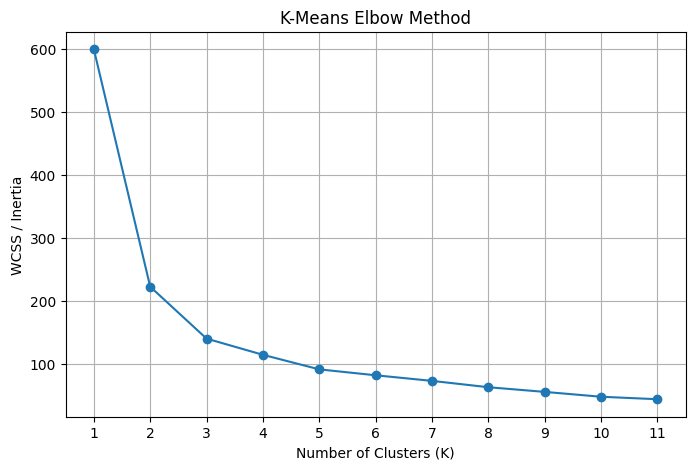

In [24]:
# Phase 3.3
# Plot the Elbow Method
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(
    k_values,
    wcss_values,
    marker="o"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### How to Read This Graph

The x-axis shows the number of clusters, K. The y-axis shows WCSS/Inertia [the total squared distance between observations and their assigned cluster centers]. A sharp drop means that adding another cluster greatly improves compactness. When the curve begins to flatten, the improvement from adding more clusters becomes smaller.

### Takeaway

WCSS falls from 600.00 at K = 1 to 222.36 at K = 2 (a drop of 377.64), and then to 139.82 at K = 3 (a drop of 82.54). After K = 3, the drops become much smaller: 25.73 from K = 3 to K = 4, 23.17 from K = 4 to K = 5, and under 11 for every step after that. The curve bends most clearly around K = 3, which makes K = 3 a candidate worth investigating. The Elbow Method does not prove that K = 3 is correct. The large drop from K = 1 to K = 2 also shows that a two-group split is strong. The final solution is checked with other evaluation methods in Phase 4.

### 3.4 K-Means: Train the Final Model

Based on the Elbow investigation, K = 3 is selected as the candidate number of clusters.

In [25]:
# Phase 3.4
# Enter the K selected from your Elbow investigation
selected_k = 3  # Replace 3 with your selected K
# Train the final K-Means model
kmeans_final = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10
)
kmeans_labels = kmeans_final.fit_predict(X_scaled)
print("Selected K:", selected_k)
print("Number of observations:", len(kmeans_labels))
print("\nK-Means cluster assignments:")
print(kmeans_labels)
print("\nCluster sizes:")
print(np.bincount(kmeans_labels))

Selected K: 3
Number of observations: 150

K-Means cluster assignments:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]

Cluster sizes:
[53 50 47]


### How to Read This

`kmeans_labels` holds the cluster assignment for each of the 150 flowers. A value of 0 means that flower was placed in cluster 0. The numbers 0, 1, and 2 are only cluster IDs. They do not stand for Iris species.

### 3.5 K-Means: Examine Cluster Sizes and Centroids

In [26]:
# Phase 3.5
# Examine K-Means cluster sizes
cluster_counts = np.bincount(kmeans_labels)
print("K-Means cluster sizes:")
for cluster_id, count in enumerate(cluster_counts):
    print(f"Cluster {cluster_id}: {count} observations")
print("=" * 70)
# Examine the final cluster centers
cluster_centers = pd.DataFrame(
    kmeans_final.cluster_centers_,
    columns=feature_names
)
print("K-Means cluster centers:")
display(cluster_centers)

K-Means cluster sizes:
Cluster 0: 53 observations
Cluster 1: 50 observations
Cluster 2: 47 observations
K-Means cluster centers:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.050220,-0.883376,0.347738,0.281527
1,-1.014579,0.853263,-1.304987,-1.254893
2,1.135970,0.088422,0.996155,1.017526


In [27]:
# Cluster sizes as a table
kmeans_size_table = pd.DataFrame({
    "K-Means Cluster": [f"Cluster {i}" for i in range(len(cluster_counts))],
    "Number of Flowers": cluster_counts,
    "Percentage of Dataset": [f"{c / cluster_counts.sum() * 100:.1f}%" for c in cluster_counts],
})

kmeans_size_table

,K-Means Cluster,Number of Flowers,Percentage of Dataset
0,Cluster 0,53,35.3%
1,Cluster 1,50,33.3%
2,Cluster 2,47,31.3%


### How to Read This

The size table shows how many of the 150 flowers were placed in each K-Means cluster. In the centroid table, each row is one cluster's centroid and each column is one feature. Because the model was trained on `X_scaled`, the centroid values are in standardized units, not centimetres. A positive value means the cluster's average for that feature is above the overall average. A negative value means it is below the overall average.

### Takeaway

K-Means placed 53 flowers in Cluster 0, 50 in Cluster 1, and 47 in Cluster 2, so the three groups are close in size. Cluster 1 has strongly negative petal length (-1.305) and petal width (-1.255) with above-average sepal width (0.853), which describes flowers with small petals. Cluster 2 has the largest values for sepal length (1.136), petal length (0.996), and petal width (1.018), which describes the largest flowers. Cluster 0 sits in between for the petal features and has the lowest sepal width (-0.883).

### 3.6 Ward's Hierarchical Clustering

Ward's Hierarchical Clustering is a second way to form groups. Hierarchical clustering [a method that builds a tree of groups by merging or splitting observations step by step] works differently from K-Means:

- K-Means works with centroids and keeps reassigning observations.
- Ward's Hierarchical Clustering starts with every observation as its own cluster and keeps merging clusters together.

Ward's method [a rule that always picks the merge that increases within-cluster variation the least] decides which two clusters to merge at each step. The process looks like this:

Individual observations → Small groups → Larger groups → Fewer groups → One large group

The `linkage()` function records every merge in a linkage matrix [a table where each row describes one merge: which two clusters were joined, the distance at which they were joined, and how many observations the new cluster holds].

In [28]:
# Phase 3.6
# Create the Ward linkage matrix
from scipy.cluster.hierarchy import linkage
Z = linkage(
    X_scaled,
    method="ward"
)
print("Ward linkage matrix shape:", Z.shape)
print("\nFirst five rows of the linkage matrix:")
display(pd.DataFrame(Z[:5]))

Ward linkage matrix shape: (149, 4)

First five rows of the linkage matrix:


,0,1,2,3
0,101.0,142.0,0.000000,2.0
1,7.0,39.0,0.121168,2.0
2,10.0,48.0,0.121168,2.0
3,0.0,17.0,0.131632,2.0
4,9.0,34.0,0.131632,2.0


### How to Read This

The linkage matrix has 149 rows because it takes 149 merges to join 150 observations into one group. In each row, columns 0 and 1 are the IDs of the two clusters being merged, column 2 is the Ward linkage distance of that merge, and column 3 is the number of observations in the new cluster. The first five merges have very small distances, which means they joined flowers with almost identical measurements. Unlike K-Means, Ward's method does not start by choosing centroids.

### 3.7 Dendrogram

A dendrogram [a tree-shaped diagram showing how observations and groups merge] shows the full hierarchy built by Ward's method.

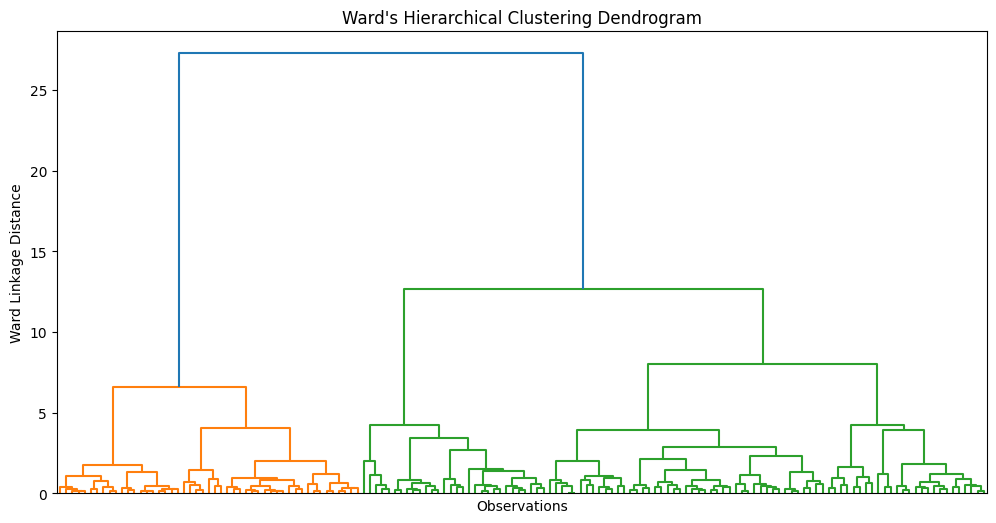

In [29]:
# Phase 3.7
# Display the Ward dendrogram
from scipy.cluster.hierarchy import dendrogram
plt.figure(figsize=(12, 6))
dendrogram(
    Z,
    no_labels=True
)
plt.xlabel("Observations")
plt.ylabel("Ward Linkage Distance")
plt.title("Ward's Hierarchical Clustering Dendrogram")
plt.show()

In [30]:
# Heights of the last five merges (the top of the dendrogram)
top_merges = pd.DataFrame({
    "Clusters Before Merge": [6, 5, 4, 3, 2],
    "Clusters After Merge": [5, 4, 3, 2, 1],
    "Ward Linkage Distance": Z[-5:, 2].round(2),
})

top_merges

,Clusters Before Merge,Clusters After Merge,Ward Linkage Distance
0,6,5,4.24
1,5,4,6.61
2,4,3,8.00
3,3,2,12.64
4,2,1,27.25


### How to Read This Graph

The dendrogram [a tree-shaped diagram showing how observations and groups merge] is read from the bottom upward. Lower merges join observations that are more similar. Larger vertical gaps show points where combining groups requires a bigger increase in Ward linkage distance.

### Takeaway

The dendrogram shows one smaller group (the orange branch on the left) splitting off from the rest (the green branch) at the top of the tree. The final merge, which joins the last two groups, happens at a Ward linkage distance of about 27.25. That is much higher than any other merge, so the clearest separation in the data is a split into two groups. The next highest merge happens at about 12.64, which is where three groups become two. The merges below that (about 8.00 and lower) are closer together. A horizontal cut between about 12.64 and 27.25 gives two groups, and a cut between about 8.00 and 12.64 gives three groups. This supports trying three groups for comparison with K-Means, while also showing that the two-group split is the strongest one.

### 3.8 Ward's Hierarchical Clustering: Final Model

To compare it directly with K-Means, the final Ward model uses the same candidate number of clusters, `selected_k`. `AgglomerativeClustering` [scikit-learn's bottom-up hierarchical clustering tool, where "agglomerative" means clusters are built by merging] is used with `linkage="ward"`.

In [31]:
# Phase 3.8
# Train the final Ward's Hierarchical Clustering model
from sklearn.cluster import AgglomerativeClustering
ward_final = AgglomerativeClustering(
    n_clusters=selected_k,
    linkage="ward"
)
ward_labels = ward_final.fit_predict(X_scaled)
print("Ward's number of clusters:", selected_k)
print("\nWard cluster assignments:")
print(ward_labels)

Ward's number of clusters: 3

Ward cluster assignments:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


In [32]:
# Ward cluster sizes as a table
ward_counts = np.bincount(ward_labels)

ward_size_table = pd.DataFrame({
    "Ward Cluster": [f"Cluster {i}" for i in range(len(ward_counts))],
    "Number of Flowers": ward_counts,
    "Percentage of Dataset": [f"{c / ward_counts.sum() * 100:.1f}%" for c in ward_counts],
})

ward_size_table

,Ward Cluster,Number of Flowers,Percentage of Dataset
0,Cluster 0,71,47.3%
1,Cluster 1,49,32.7%
2,Cluster 2,30,20.0%


### How to Read This

Both algorithms used the same standardized data (`X_scaled`). K-Means results are stored in `kmeans_labels`, and Ward results are stored in `ward_labels`. The cluster numbers are assigned separately by each algorithm, so K-Means Cluster 0 and Ward Cluster 0 are not necessarily the same group.

### Takeaway

Ward placed 71 flowers in Cluster 0, 49 in Cluster 1, and 30 in Cluster 2. These groups are less even in size than the K-Means groups.

### 3.9 Compare the Two Cluster Solutions

This is a basic comparison of the structure of the two solutions before any formal evaluation.

In [33]:
# Phase 3.9
# Compare the basic cluster structure
print("=" * 70)
print("PHASE 3: CLUSTERING RESULTS")
print("=" * 70)
print("Selected K:", selected_k)
print("\nK-Means cluster sizes:")
print(np.bincount(kmeans_labels))
print("\nWard cluster sizes:")
print(np.bincount(ward_labels))
print("\nNumber of K-Means clusters:", len(np.unique(kmeans_labels)))
print("\nNumber of Ward clusters:", len(np.unique(ward_labels)))

PHASE 3: CLUSTERING RESULTS
Selected K: 3

K-Means cluster sizes:
[53 50 47]

Ward cluster sizes:
[71 49 30]

Number of K-Means clusters: 3

Number of Ward clusters: 3


In [34]:
# Cluster sizes from both algorithms, sorted from largest to smallest
# (sorted because the cluster ID numbers do not match between the two algorithms)
size_comparison = pd.DataFrame({
    "Size Rank": ["Largest cluster", "Middle cluster", "Smallest cluster"],
    "K-Means Cluster Size": sorted(np.bincount(kmeans_labels), reverse=True),
    "Ward Cluster Size": sorted(np.bincount(ward_labels), reverse=True),
})

size_comparison

,Size Rank,K-Means Cluster Size,Ward Cluster Size
0,Largest cluster,53,71
1,Middle cluster,50,49
2,Smallest cluster,47,30


### How to Read This

The table lines up the cluster sizes from largest to smallest, because the cluster ID numbers from the two algorithms do not refer to the same groups.

### Takeaway

Both algorithms produced three clusters. K-Means produced groups of 53, 50, and 47 flowers. Ward produced groups of 71, 49, and 30 flowers. Both methods found one group of about 50 flowers, but they divided the remaining flowers differently. These basic counts do not show which solution is better. That is tested in Phase 4.

## Phase 3 Questions

### Q17: Why does WCSS/Inertia generally decrease as K increases? Why does a lower WCSS by itself not tell us which K is most useful?

WCSS/Inertia (the total squared distance between each data point and the center of its cluster) usually gets lower as K increases because more clusters means more centroids (the center points of the clusters). With more centroids available, the flowers can usually be assigned to a closer one. The problem is that WCSS will keep dropping as more clusters are added, so the lowest number does not automatically mean the best choice. In this activity, WCSS went from 600.00 at K = 1 all the way down to 43.47 at K = 11. The useful part is looking for where the improvement starts getting much smaller instead of just picking the biggest K.

### Q20: If one cluster contains substantially more observations than another, what might this tell us about the structure of the data?

A much bigger cluster can mean that more observations have similar measurement patterns and are getting grouped together. It can also mean that some groups overlap enough that the algorithm is combining them instead of separating them cleanly. In this activity, Ward created clusters with 71, 49, and 30 flowers, even though the real species groups each had 50. The contingency table (a table showing how the real species were spread across the discovered clusters) helps explain this because Ward's largest cluster contains both Virginica and Versicolor flowers. That shows why looking at cluster size by itself is not enough to decide whether the result is good or bad.

### Q24: Based on the Elbow plot, what value or range of K appears reasonable? What evidence supports your choice?

K = 3 looks like a reasonable choice from the Elbow plot. WCSS drops a lot from 600.00 at K = 1 to 222.36 at K = 2, and then drops again to 139.82 at K = 3. After K = 3, the improvements get much smaller overall. This creates the visible "elbow" (the point where adding more clusters starts helping less). That makes K = 3 a reasonable candidate to keep testing. It does not prove that 3 is the only correct answer, which is why the clustering is checked again later using other evaluation methods.

### Phase 3 Checkpoint

The following objects now exist:

| Variable | Contents |
|---|---|
| `X_scaled` | Standardized feature data |
| `selected_k` | Candidate number of clusters |
| `kmeans_final` | Final K-Means model |
| `kmeans_labels` | K-Means cluster assignments |
| `cluster_centers` | K-Means centroids |
| `Z` | Ward linkage matrix |
| `ward_final` | Final Ward model |
| `ward_labels` | Ward cluster assignments |

## Phase 4: Evaluation and Validation

This phase evaluates the quality and consistency of the clusters found in Phase 3. It uses:

- **Silhouette Score:** how well each observation fits its own cluster.
- **Davies-Bouldin Index:** how compact and well separated the clusters are.
- **Adjusted Rand Index (ARI):** how closely the clusters match the known species.
- **Contingency Table:** how many flowers of each species landed in each cluster.
- **Stability Analysis:** whether K-Means gives the same result when it is run again.

**Important:** This is the first phase where `y_true` is used. The clustering algorithms never received `y_true`. The known species labels are used here only for external validation [checking the results against outside information, in this case the real species].

### 4.1 Prepare the Cluster Results

This step confirms that the cluster assignments from Phase 3 are available.

In [35]:
# Phase 4.1
# Confirm the cluster results from Phase 3
print("=" * 70)
print("PHASE 4: EVALUATION & VALIDATION")
print("=" * 70)
print("Number of observations:", len(X_scaled))
print("\nK-Means clusters:")
print(np.unique(kmeans_labels))
print("K-Means cluster sizes:")
print(np.bincount(kmeans_labels))
print("\nWard clusters:")
print(np.unique(ward_labels))
print("\nWard cluster sizes:")
print(np.bincount(ward_labels))
print("\nKnown classes:")
print(np.unique(y_true))
print("\nKnown class names:")
print(class_names)

PHASE 4: EVALUATION & VALIDATION
Number of observations: 150

K-Means clusters:
[0 1 2]
K-Means cluster sizes:
[53 50 47]

Ward clusters:
[0 1 2]

Ward cluster sizes:
[71 49 30]

Known classes:
[0 1 2]

Known class names:
['setosa' 'versicolor' 'virginica']


### How to Read This

Every one of the 150 observations has a K-Means label and a Ward label. The known species labels are stored separately in `y_true`. They can now be used for evaluation, but the cluster assignments are not changed based on them.

### 4.2 Silhouette Score

The Silhouette Score [a number from about -1 to +1 that compares how close each observation is to its own cluster versus the nearest other cluster] considers two ideas:

1. How close an observation is to the other observations in its own cluster.
2. How far the observation is from the observations in the nearest other cluster.

A value closer to +1 means better separation and cohesion [how tightly the members of a cluster sit together]. A value around 0 means observations may sit near cluster boundaries. A negative value may mean some observations would fit better in another cluster. This score does not use `y_true`.

In [36]:
# Phase 4.2
# Calculate Silhouette Score for both clustering solutions
from sklearn.metrics import silhouette_score
kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels
)
ward_silhouette = silhouette_score(
    X_scaled,
    ward_labels
)
print("Silhouette Score")
print("=" * 70)
print("K-Means:", round(kmeans_silhouette, 4))
print("Ward:", round(ward_silhouette, 4))

Silhouette Score
K-Means: 0.4599
Ward: 0.4467


### Takeaway

K-Means has a Silhouette Score of 0.4599 and Ward has 0.4467. Both values are positive and moderate, and K-Means is slightly higher. This suggests both solutions have a reasonable cluster structure, with some observations sitting near cluster boundaries.

### 4.3 Davies-Bouldin Index

The Davies-Bouldin Index [a score that compares each cluster with its most similar neighbouring cluster, based on how compact and how far apart they are] looks at cluster compactness and separation. For this metric, lower values generally mean a better cluster structure. Like the Silhouette Score, it does not use `y_true`.

In [37]:
# Phase 4.3
# Calculate Davies-Bouldin Index for both clustering solutions
from sklearn.metrics import davies_bouldin_score
kmeans_db = davies_bouldin_score(
    X_scaled,
    kmeans_labels
)
ward_db = davies_bouldin_score(
    X_scaled,
    ward_labels
)
print("Davies-Bouldin Index")
print("=" * 70)
print("K-Means:", round(kmeans_db, 4))
print("Ward:", round(ward_db, 4))

Davies-Bouldin Index
K-Means: 0.8336
Ward: 0.8035


### Takeaway

K-Means has a Davies-Bouldin Index of 0.8336 and Ward has 0.8035. Because lower is better for this metric, Ward scores slightly better here. This is the opposite direction from the Silhouette Score result, so the two internal metrics do not agree on which method has the better structure. Both differences are small.

### 4.4 Adjusted Rand Index (ARI)

The Adjusted Rand Index [a score that measures how closely two groupings agree, adjusted so that random agreement scores about 0] compares the discovered clusters with the known Iris species in `y_true`. It can range from -1 to 1. Values near 0 mean agreement close to chance, and higher values mean stronger agreement.

The cluster numbers do not need to match the species numbers. ARI checks whether the same flowers are grouped together, not whether the labels have the same names.

In [38]:
# Phase 4.4
# Compare discovered clusters with the known species labels
from sklearn.metrics import adjusted_rand_score
kmeans_ari = adjusted_rand_score(
    y_true,
    kmeans_labels
)
ward_ari = adjusted_rand_score(
    y_true,
    ward_labels
)
print("Adjusted Rand Index (ARI)")
print("=" * 70)
print("K-Means:", round(kmeans_ari, 4))
print("Ward:", round(ward_ari, 4))

Adjusted Rand Index (ARI)
K-Means: 0.6201
Ward: 0.6153


### How to Read This

The comparison works like this:

```
Known species (y_true)
       ↓
   ┌───┴───┐
   ↓       ↓
K-Means   Ward
 labels   labels
   ↓       ↓
  ARI     ARI
```

### Takeaway

K-Means has an ARI of 0.6201 and Ward has 0.6153. Both show clear agreement with the known species, well above chance, but neither matches the species perfectly. The two scores are very close, with K-Means slightly higher.

### 4.5 Contingency Table

A contingency table [a count table that shows how two sets of labels line up, here the known species against the discovered clusters] shows how many flowers of each species were placed in each cluster. It gives more detail than a single ARI score.

In [39]:
# Phase 4.5
# Create contingency tables for K-Means and Ward
kmeans_contingency = pd.crosstab(
    pd.Series(y_true, name="True Species"),
    pd.Series(kmeans_labels, name="K-Means Cluster")
)
ward_contingency = pd.crosstab(
    pd.Series(y_true, name="True Species"),
    pd.Series(ward_labels, name="Ward Cluster")
)
# Replace numeric species IDs with species names
kmeans_contingency.index = class_names[kmeans_contingency.index]
ward_contingency.index = class_names[ward_contingency.index]
print("K-Means Contingency Table")
print("=" * 70)
display(kmeans_contingency)
print("\nWard Contingency Table")
print("=" * 70)
display(ward_contingency)

K-Means Contingency Table


K-Means Cluster,0,1,2
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36



Ward Contingency Table


Ward Cluster,0,1,2
setosa,0,49,1
versicolor,23,0,27
virginica,48,0,2


### How to Read This

Each row is a known species and each column is a discovered cluster. Each number is the count of flowers of that species placed in that cluster. Each row adds up to 50. The cluster numbers were not renamed to match the species.

### Takeaway

**K-Means:** All 50 Setosa flowers are together in Cluster 1, and no other species is in that cluster. Versicolor is split, with 39 flowers in Cluster 0 and 11 in Cluster 2. Virginica is also split, with 36 flowers in Cluster 2 and 14 in Cluster 0. This means K-Means separates Setosa cleanly, but Clusters 0 and 2 mix Versicolor and Virginica.

**Ward:** 49 Setosa flowers are in Cluster 1 and 1 Setosa flower is in Cluster 2. Virginica stays mostly together, with 48 flowers in Cluster 0 and 2 in Cluster 2. Versicolor is split almost in half, with 23 flowers in Cluster 0 and 27 in Cluster 2. This means Ward's Cluster 0 holds nearly all of Virginica plus about half of Versicolor.

In both tables, Setosa is the easiest species to separate, and most of the disagreement comes from Versicolor and Virginica.

### 4.6 Visualizing the Clustering Results

These scatter plots compare the known species with the clusters found by K-Means and Ward. The models were trained on all four standardized features in `X_scaled`, but the plots use only the two features in `X_viz` so the results can be drawn in two dimensions.

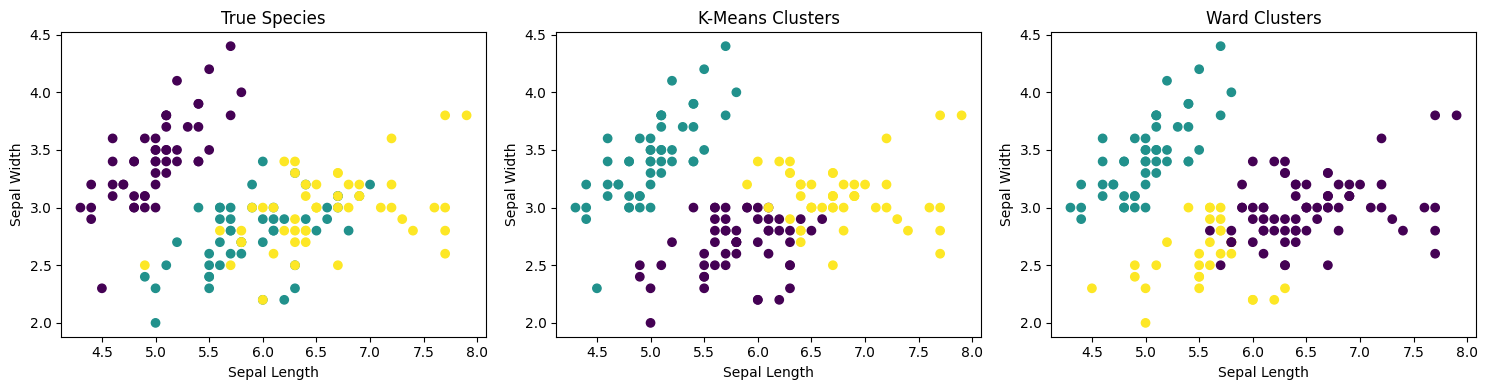

In [40]:
# Phase 4.6
# Visualize the known species and discovered clusters
plt.figure(figsize=(15, 4))
# 1. Known species
plt.subplot(1, 3, 1)
plt.scatter(
    X_viz[:, 0],
    X_viz[:, 1],
    c=y_true
)
plt.title("True Species")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
# 2. K-Means clusters
plt.subplot(1, 3, 2)
plt.scatter(
    X_viz[:, 0],
    X_viz[:, 1],
    c=kmeans_labels
)
plt.title("K-Means Clusters")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
# 3. Ward clusters
plt.subplot(1, 3, 3)
plt.scatter(
    X_viz[:, 0],
    X_viz[:, 1],
    c=ward_labels
)
plt.title("Ward Clusters")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.tight_layout()
plt.show()

### How to Read These Graphs

Each dot represents one flower. The first graph uses the known species labels. The second and third graphs use the groups discovered by K-Means and Ward's clustering. Only sepal length and sepal width are shown in these graphs, even though all four standardized features were used to train the clustering models. Colours only separate groups within each graph. The same colour in two graphs does not mean the same group.

### Takeaway

In all three graphs, most flowers with shorter and wider sepals form a separate group in the upper left. This matches Setosa, which both methods separated in the contingency tables. The remaining flowers overlap heavily in sepal length and sepal width, and the boundary between the two remaining groups is drawn differently in each graph. This matches the Versicolor and Virginica mixing shown in the contingency tables. Because only two of the four features are shown, these plots are a visual aid and not a full measure of clustering quality.

### 4.7 Clustering Stability

A clustering solution should not depend heavily on one particular random start. K-Means begins with randomly chosen centroids, so different starts can sometimes give different results.

To check this, K-Means is run 10 more times with different random seeds [starting numbers that control the random choices, so a run can be repeated exactly]. Each new result is compared with the original K-Means solution using ARI. An ARI of 1.0 means the two runs grouped the flowers in exactly the same way.

In [41]:
# Phase 4.7
# Investigate K-Means clustering stability
from sklearn.metrics import adjusted_rand_score
stability_scores = []
for seed in range(10):
    kmeans_test = KMeans(
        n_clusters=selected_k,
        random_state=seed,
        n_init=10
    )
    test_labels = kmeans_test.fit_predict(X_scaled)
    # Compare this run with the original K-Means solution
    score = adjusted_rand_score(
        kmeans_labels,
        test_labels
    )
    stability_scores.append(score)
print("K-Means Stability")
print("=" * 70)
print("Average ARI across runs:",
      round(np.mean(stability_scores), 4))
print("Minimum ARI:",
      round(np.min(stability_scores), 4))
print("Maximum ARI:",
      round(np.max(stability_scores), 4))

K-Means Stability
Average ARI across runs: 0.9921
Minimum ARI: 0.9412
Maximum ARI: 1.0


In [42]:
# ARI for each individual run compared with the original K-Means solution
stability_table = pd.DataFrame({
    "Random Seed": list(range(10)),
    "ARI vs Original K-Means": np.round(stability_scores, 4),
})

stability_table

,Random Seed,ARI vs Original K-Means
0,0,1.0000
1,1,1.0000
2,2,1.0000
3,3,1.0000
4,4,0.9799
5,5,1.0000
6,6,0.9412
7,7,1.0000
8,8,1.0000
9,9,1.0000


### How to Read This

Each row is one extra K-Means run with a different random seed. The ARI column shows how closely that run matches the original K-Means solution (which used `random_state=42`).

### Takeaway

The average ARI across the 10 runs is 0.9921, the minimum is 0.9412 (seed 6), and the maximum is 1.0. Eight of the ten runs matched the original solution exactly. Seeds 4 and 6 were slightly different but still very close. This indicates the K-Means solution is highly consistent across different starting points. This test only checks K-Means starting-point stability. It does not test other changes such as resampling the data, adding noise, or removing observations.

### 4.8 Evaluation Summary

In [43]:
# Phase 4.8
# Summarize the main evaluation results
evaluation_results = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Adjusted Rand Index"
    ],
    "K-Means": [
        kmeans_silhouette,
        kmeans_db,
        kmeans_ari
    ],
    "Ward": [
        ward_silhouette,
        ward_db,
        ward_ari
    ]
})
print("=" * 70)
print("PHASE 4: EVALUATION SUMMARY")
print("=" * 70)
display(evaluation_results.round(4))

PHASE 4: EVALUATION SUMMARY


,Metric,K-Means,Ward
0,Silhouette Score,0.4599,0.4467
1,Davies-Bouldin Index,0.8336,0.8035
2,Adjusted Rand Index,0.6201,0.6153


In [44]:
# Same results with a plain-language guide for each metric
evaluation_guide = evaluation_results.round(4).copy()
evaluation_guide["How to Interpret"] = [
    "Higher is generally better",
    "Lower is generally better",
    "Higher agreement with true species is generally better",
]

evaluation_guide

,Metric,K-Means,Ward,How to Interpret
0,Silhouette Score,0.4599,0.4467,Higher is generally better
1,Davies-Bouldin Index,0.8336,0.8035,Lower is generally better
2,Adjusted Rand Index,0.6201,0.6153,Higher agreement with true species is generally better


### How to Read This Table

The three metrics evaluate different parts of the clustering results. Silhouette Score and Davies-Bouldin Index evaluate the internal cluster structure without using the true species labels. Adjusted Rand Index uses the true species labels only after clustering to measure how closely the discovered grouping matches the known classes.

### Takeaway

The results are close and do not all point the same way:

- Silhouette Score: K-Means 0.4599, Ward 0.4467. K-Means is slightly higher (better).
- Davies-Bouldin Index: K-Means 0.8336, Ward 0.8035. Ward is slightly lower (better).
- Adjusted Rand Index: K-Means 0.6201, Ward 0.6153. K-Means is slightly higher (better).

K-Means is ahead on two of the three metrics, but every gap is small. Both methods separate Setosa almost perfectly and both mix Versicolor with Virginica. The K-Means solution was also very stable across random starts, with an average stability ARI of 0.9921. These metrics answer different questions, so they should be read together and not treated as interchangeable.

## Phase 4 Questions

The contents section of the Activity 4 instructions lists "Phase 4 Questions (Q28 to Q30)". The instructions do not include the wording for these questions, so they are not written here.

## Phase 5: Deployment and Operationalization

Deployment [putting a trained model into use so it can handle new data] is the focus of this phase. The steps are:

1. Save the preprocessing and the clustering model.
2. Receive a new Iris observation.
3. Apply the same preprocessing used during training.
4. Use the trained K-Means model to assign the new observation to a cluster.
5. Examine an important deployment limitation of Ward's Hierarchical Clustering.

**Important MLOps principle:** A deployed model must process new data using the same preprocessing steps used during training. A new scaler must not be fitted on the new observation.

The deployment flow is:

```
Original new flower measurements
→ saved scaler
→ standardized flower
→ trained K-Means model
→ cluster assignment
```

### 5.1 Save the Preprocessing and K-Means Model

The fitted scaler and the trained model are deployment assets [the saved files a live system needs to make predictions]. `joblib` saves Python objects to files, often called pickle files [`.pkl` files that store a Python object so it can be loaded again later]. Saving them means the same preprocessing and model can be reused later without retraining each time new data arrives.

In [45]:
# Phase 5.1
# Save the fitted scaler and trained K-Means model
import joblib
joblib.dump(
    scaler,
    "iris_scaler.pkl"
)
joblib.dump(
    kmeans_final,
    "iris_kmeans_model.pkl"
)
print("Scaler saved: iris_scaler.pkl")
print("K-Means model saved: iris_kmeans_model.pkl")

Scaler saved: iris_scaler.pkl
K-Means model saved: iris_kmeans_model.pkl


### Takeaway

The scaler (with the feature means and standard deviations learned in Phase 2) is saved as `iris_scaler.pkl`. The K-Means model (with its three learned centroids) is saved as `iris_kmeans_model.pkl`. The files are saved in the same folder as this notebook.

### 5.2 Simulate a New Observation

A new iris flower arrives at the research institute. It has the same four measurements used to train the model. No species label is given, because the clustering model does not need one to assign the flower to a cluster.

In [46]:
# Phase 5.2
# Create a new observation
new_flower = np.array([
    [5.9, 3.0, 5.1, 1.8]
])
print("New observation:")
print(new_flower)
print("\nShape:")
print(new_flower.shape)

New observation:
[[5.9 3.  5.1 1.8]]

Shape:
(1, 4)


### How to Read This

The shape `(1, 4)` means one flower with four measurements, in the same order as the training features: sepal length 5.9 cm, sepal width 3.0 cm, petal length 5.1 cm, and petal width 1.8 cm.

### 5.3 Apply the Saved Preprocessing

The new observation is standardized with the existing fitted scaler using `scaler.transform()`, not `scaler.fit_transform()`. The scaler was already fitted in Phase 2. Using `transform()` makes sure the new flower is rescaled with the same means and standard deviations learned from the training data. Fitting a new scaler on a single flower would produce meaningless values.

In [47]:
# Phase 5.3
# Transform the new observation using the fitted scaler
new_flower_scaled = scaler.transform(new_flower)
print("Standardized new observation:")
print(new_flower_scaled)

Standardized new observation:
[[ 0.06866179 -0.13197948  0.76275827  0.79067065]]


In [48]:
# Original and standardized values side by side
new_flower_table = pd.DataFrame({
    "Feature": feature_names,
    "Original Measurement (cm)": new_flower[0],
    "Standardized Value": new_flower_scaled[0].round(4),
})

new_flower_table

,Feature,Original Measurement (cm),Standardized Value
0,sepal length (cm),5.9,0.0687
1,sepal width (cm),3.0,-0.1320
2,petal length (cm),5.1,0.7628
3,petal width (cm),1.8,0.7907


### How to Read This

Each standardized value shows how far the new flower is from the training average for that feature, in standard deviations. The sepal length (0.0687) is very close to average and the sepal width (-0.132) is slightly below average. The petal length (0.7628) and petal width (0.7907) are both clearly above average.

### 5.4 Assign the New Observation Using K-Means

K-Means has a `predict()` method [a function that assigns new data using what the model already learned] that places a new observation in the cluster with the nearest learned centroid.

In [49]:
# Phase 5.4
# Assign the new observation to a K-Means cluster
new_cluster = kmeans_final.predict(
    new_flower_scaled
)
print("Predicted K-Means cluster:", new_cluster[0])

Predicted K-Means cluster: 0


In [50]:
# Distance from the new flower to each learned centroid
centroid_distances = np.linalg.norm(
    kmeans_final.cluster_centers_ - new_flower_scaled, axis=1
)

distance_table = pd.DataFrame({
    "K-Means Cluster": [f"Cluster {i}" for i in range(len(centroid_distances))],
    "Distance to Centroid": centroid_distances.round(4),
})

distance_table

,K-Means Cluster,Distance to Centroid
0,Cluster 0,1.0051
1,Cluster 1,3.2564
2,Cluster 2,1.1374


### How to Read This

The distance table shows the Euclidean distance from the standardized new flower to each K-Means centroid. `predict()` picks the cluster with the smallest distance.

### Takeaway

The new flower is assigned to K-Means Cluster 0 because that centroid is the closest one. The cluster ID is a discovered group identifier, not a species name. Cluster 0, Cluster 1, and Cluster 2 do not automatically mean Setosa, Versicolor, and Virginica. In the Phase 4 contingency table, K-Means Cluster 0 held 39 Versicolor and 14 Virginica flowers.

### 5.5 Important Deployment Limitation: Ward

Ward's Hierarchical Clustering behaves differently from K-Means when new observations arrive. scikit-learn's standard `AgglomerativeClustering` builds a hierarchy only from the observations it was trained on. It does not provide the same simple `predict()` method that K-Means has. This means the following line would not work the same way:

```python
ward_final.predict(new_flower_scaled)
```

Instead of running that line and causing an error, the check below asks each model whether it has a `predict()` method.

In [51]:
# Check which trained models offer a predict() method
predict_check = pd.DataFrame({
    "Model": ["K-Means (kmeans_final)", "Ward (ward_final)"],
    "Has predict()": [hasattr(kmeans_final, "predict"), hasattr(ward_final, "predict")],
})

predict_check

,Model,Has predict()
0,K-Means (kmeans_final),True
1,Ward (ward_final),False


### Takeaway

The check confirms that `kmeans_final` has a `predict()` method and `ward_final` does not. K-Means learns a set of centroids that can be reused to assign future observations. Ward's method only builds a hierarchy for the observations it was given. If Ward's clustering were chosen for a live system, the design would need another strategy, such as:

- retraining the hierarchy with updated data,
- using a separate assignment strategy, or
- choosing a clustering approach that supports direct prediction of new observations.

## Phase 5 Questions

### Q40: Why is K-Means easier to use for assigning new observations than standard Ward's Agglomerative Clustering?

K-Means is easier to use with new data because it keeps the learned centroids (the center points of the clusters) and has a predict() method. A new flower can be standardized with the saved scaler, compared with those centroids, and then assigned to the closest cluster. Ward's Agglomerative Clustering works differently because it builds a hierarchy (a tree-like structure showing how observations are grouped together) from the data that was already there during training. It does not have the same direct predict() method for a brand-new observation, so assigning new data would need a different approach or the hierarchy would need to be rebuilt.

### Phase 5 Checkpoint

| Variable | Contents |
|---|---|
| `scaler` | Fitted preprocessing object |
| `kmeans_final` | Trained K-Means model |
| `new_flower` | New observation |
| `new_flower_scaled` | Standardized new observation |
| `new_cluster` | K-Means cluster assignment |

## Appendix: Quick Reference, K-Means vs Ward's

| Aspect | K-Means | Ward's Hierarchical |
|---|---|---|
| Number of clusters | Must choose K upfront | Choose K after building the tree |
| Training speed | Fast, scalable | Slow, O(n²) |
| Cluster shape | Assumes spherical | Any shape |
| New data | `predict()` works easily | No direct `predict()` |
| Output | Cluster labels | Cluster labels + dendrogram |
| Stability | Depends on initialization | Deterministic |
| Best for | Large datasets, real-time scoring | Small datasets, hierarchy exploration |

### Key Takeaways

- K-Means commits to K upfront, uses centroids, and can score new data easily.
- Ward's builds a full hierarchy and allows K to be chosen afterward, but it cannot easily score new data.
- Standardization is required for both algorithms because they rely on Euclidean distance.
- External validation (ARI and contingency tables) uses the known labels, but only after clustering is complete.
- Deployment requires saving the scaler alongside the model, and K-Means is much easier to put into operation than Ward's.